In [ ]:
from pathlib import Path
import logging
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display

try:
    import pm4py
    PM4PY_AVAILABLE = True
except ImportError:
    pm4py = None
    PM4PY_AVAILABLE = False

logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")
LOGGER = logging.getLogger("careflow")
warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_SEED = 42
N_PATIENTS = 500
TARGET_TRIAGE_RETURN_RATE = 0.40
START_DATE = pd.Timestamp("2026-01-01 00:00:00")
SIMULATION_DAYS = 28
OUTPUT_DIR = Path("careflow_data")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"CareFlow configuration | cases={N_PATIENTS:,} | target rework={TARGET_TRIAGE_RETURN_RATE:.0%}")
print(f"Output directory: {OUTPUT_DIR.resolve()}")
print(f"PM4Py available: {PM4PY_AVAILABLE}")

CareFlow configuration | cases=500 | target rework=40%
Output directory: /mnt/data/CareFlow_Project/careflow_data
PM4Py available: False


In [ ]:
ACTIVITY_DEPARTMENT = {
    "Registration": "Front Desk",
    "Triage": "Emergency Department",
    "Physician Assessment": "Emergency Department",
    "X-Ray": "Radiology",
    "Paperwork Completion": "Patient Intake",
    "Physician Reassessment": "Emergency Department",
    "Treatment": "Emergency Department",
    "Discharge": "Emergency Department",
}


def _arrival_shift(timestamp: pd.Timestamp) -> str:
    hour = timestamp.hour
    if 6 <= hour < 12:
        return "Morning (06:00–11:59)"
    if 12 <= hour < 18:
        return "Afternoon (12:00–17:59)"
    return "Night (18:00–05:59)"


def generate_synthetic_event_log(
    n_patients: int = 500,
    triage_return_rate: float = 0.40,
    seed: int = 42,
    start_date: pd.Timestamp = pd.Timestamp("2026-01-01 00:00:00"),
    simulation_days: int = 28,
) -> pd.DataFrame:
    """Create an event-level, synthetic ER log with a controlled triage-return pattern."""
    if n_patients < 1:
        raise ValueError("n_patients must be at least 1")
    if not 0 <= triage_return_rate <= 1:
        raise ValueError("triage_return_rate must be between 0 and 1")
    if simulation_days < 1:
        raise ValueError("simulation_days must be at least 1")

    rng = np.random.default_rng(seed)
    n_return_cases = int(round(n_patients * triage_return_rate))
    return_case_indices = set(rng.choice(n_patients, size=n_return_cases, replace=False).tolist())
    records = []
    age_bands = np.array(["0–17", "18–39", "40–64", "65+"])
    age_probabilities = [0.08, 0.38, 0.34, 0.20]

    for idx in range(n_patients):
        case_id = f"CF-{idx + 1:06d}"
        arrival = start_date + pd.Timedelta(
            minutes=int(rng.integers(0, simulation_days * 24 * 60))
        )
        age_band = str(rng.choice(age_bands, p=age_probabilities))
        shift = _arrival_shift(arrival)
        requires_rework = idx in return_case_indices
        ts = arrival
        case_events = []

        def add_event(activity, minutes_after_previous=0, return_reason=None):
            nonlocal ts
            ts = ts + pd.Timedelta(minutes=int(minutes_after_previous))
            if not case_events:
                ts = arrival
            if activity in {"Physician Assessment", "Physician Reassessment"}:
                resource_id = f"DR-{int(rng.integers(1, 9)):02d}"
            elif activity == "X-Ray":
                resource_id = f"RAD-{int(rng.integers(1, 5)):02d}"
            elif activity == "Triage":
                resource_id = f"TRI-{int(rng.integers(1, 7)):02d}"
            else:
                resource_id = f"OPS-{int(rng.integers(1, 6)):02d}"

            case_events.append({
                "Case_ID": case_id,
                "Activity_Name": activity,
                "Timestamp": ts,
                "Department": ACTIVITY_DEPARTMENT[activity],
                "Resource_ID": resource_id,
                "Age_Band": age_band,
                "Arrival_Shift": shift,
                "Rework_Expected": bool(requires_rework),
                "Return_Reason": return_reason,
                "Is_Synthetic": True,
            })

        add_event("Registration")
        add_event("Triage", rng.integers(5, 19))
        add_event("Physician Assessment", rng.integers(10, 46))
        add_event("X-Ray", rng.integers(15, 51))

        if requires_rework:
            add_event("Triage", rng.integers(15, 46), return_reason="Missing intake paperwork")
            add_event("Paperwork Completion", rng.integers(5, 21))

        add_event("Physician Reassessment", rng.integers(10, 46) if requires_rework else rng.integers(5, 26))
        add_event("Treatment", rng.integers(10, 41))
        add_event("Discharge", rng.integers(5, 31))
        records.extend(case_events)

    event_log = pd.DataFrame.from_records(records)
    event_log["Timestamp"] = pd.to_datetime(event_log["Timestamp"], errors="raise")
    event_log = event_log.sort_values(["Case_ID", "Timestamp"]).reset_index(drop=True)
    return event_log


event_log = generate_synthetic_event_log(
    n_patients=N_PATIENTS,
    triage_return_rate=TARGET_TRIAGE_RETURN_RATE,
    seed=RANDOM_SEED,
    start_date=START_DATE,
    simulation_days=SIMULATION_DAYS,
)

raw_path = OUTPUT_DIR / "raw_event_log.csv"
event_log.to_csv(raw_path, index=False, date_format="%Y-%m-%d %H:%M:%S")

print(f"Generated {len(event_log):,} event records across {event_log['Case_ID'].nunique():,} cases.")
display(event_log.head(12))

Generated 3,900 event records across 500 cases.


,Case_ID,Activity_Name,Timestamp,Department,Resource_ID,Age_Band,Arrival_Shift,Rework_Expected,Return_Reason,Is_Synthetic
0,CF-000001,Registration,2026-01-09 16:32:00,Front Desk,OPS-02,40–64,Afternoon (12:00–17:59),False,None,True
1,CF-000001,Triage,2026-01-09 16:50:00,Emergency Department,TRI-03,40–64,Afternoon (12:00–17:59),False,None,True
2,CF-000001,Physician Assessment,2026-01-09 17:18:00,Emergency Department,DR-04,40–64,Afternoon (12:00–17:59),False,None,True
3,CF-000001,X-Ray,2026-01-09 17:38:00,Radiology,RAD-04,40–64,Afternoon (12:00–17:59),False,None,True
4,CF-000001,Physician Reassessment,2026-01-09 17:43:00,Emergency Department,DR-02,40–64,Afternoon (12:00–17:59),False,None,True
5,CF-000001,Treatment,2026-01-09 18:00:00,Emergency Department,OPS-02,40–64,Afternoon (12:00–17:59),False,None,True
6,CF-000001,Discharge,2026-01-09 18:08:00,Emergency Department,OPS-01,40–64,Afternoon (12:00–17:59),False,None,True
7,CF-000002,Registration,2026-01-19 23:23:00,Front Desk,OPS-02,18–39,Night (18:00–05:59),False,None,True
8,CF-000002,Triage,2026-01-19 23:35:00,Emergency Department,TRI-06,18–39,Night (18:00–05:59),False,None,True
9,CF-000002,Physician Assessment,2026-01-20 00:09:00,Emergency Department,DR-07,18–39,Night (18:00–05:59),False,None,True


In [ ]:
REQUIRED_COLUMNS = ["Case_ID", "Activity_Name", "Timestamp"]


def validate_event_log(data: pd.DataFrame) -> pd.DataFrame:
    checks = []
    missing_columns = sorted(set(REQUIRED_COLUMNS) - set(data.columns))
    checks.append({
        "Check": "Required process-mining columns exist",
        "Passed": len(missing_columns) == 0,
        "Details": "All required columns present" if not missing_columns else f"Missing: {missing_columns}",
    })
    if missing_columns:
        return pd.DataFrame(checks)

    checks.append({
        "Check": "No null Case_ID / Activity_Name / Timestamp values",
        "Passed": bool(data[REQUIRED_COLUMNS].notna().all().all()),
        "Details": f"Rows with missing required values: {int(data[REQUIRED_COLUMNS].isna().any(axis=1).sum())}",
    })
    checks.append({
        "Check": "No exact duplicate event records",
        "Passed": int(data.duplicated().sum()) == 0,
        "Details": f"Duplicate rows: {int(data.duplicated().sum())}",
    })
    parsed_ts = pd.to_datetime(data["Timestamp"], errors="coerce")
    checks.append({
        "Check": "All timestamps are valid datetimes",
        "Passed": bool(parsed_ts.notna().all()),
        "Details": f"Unparseable timestamps: {int(parsed_ts.isna().sum())}",
    })

    ordered = data.assign(_timestamp=parsed_ts).sort_values(["Case_ID", "_timestamp"])
    deltas = ordered.groupby("Case_ID", sort=False)["_timestamp"].diff()
    negative_or_equal = int((deltas <= pd.Timedelta(0)).sum())
    checks.append({
        "Check": "Timestamps strictly increase within each case",
        "Passed": negative_or_equal == 0,
        "Details": f"Non-increasing timestamp steps: {negative_or_equal}",
    })

    activity_counts = data.groupby(["Case_ID", "Activity_Name"]).size().unstack(fill_value=0)
    registration_issues = int((activity_counts.get("Registration", pd.Series(0, index=activity_counts.index)) != 1).sum())
    discharge_issues = int((activity_counts.get("Discharge", pd.Series(0, index=activity_counts.index)) != 1).sum())
    checks.append({
        "Check": "Exactly one Registration and one Discharge per case",
        "Passed": registration_issues == 0 and discharge_issues == 0,
        "Details": f"Cases with registration count issue: {registration_issues}; discharge count issue: {discharge_issues}",
    })
    return pd.DataFrame(checks)


quality_report = validate_event_log(event_log)
display(quality_report)

if not quality_report["Passed"].all():
    failed = quality_report.loc[~quality_report["Passed"], "Check"].tolist()
    raise ValueError(f"Event-log validation failed: {failed}")

# Normalize the core columns and retain the additional context columns for analysis.
event_log["Case_ID"] = event_log["Case_ID"].astype("string")
event_log["Activity_Name"] = event_log["Activity_Name"].astype("string").str.strip()
event_log["Timestamp"] = pd.to_datetime(event_log["Timestamp"], errors="raise")
event_log = event_log.sort_values(["Case_ID", "Timestamp"]).reset_index(drop=True)
print("Validation passed. The event log is ready for process analysis.")

,Check,Passed,Details
0,Required process-mining columns exist,True,All required columns present
1,No null Case_ID / Activity_Name / Timestamp va...,True,Rows with missing required values: 0
2,No exact duplicate event records,True,Duplicate rows: 0
3,All timestamps are valid datetimes,True,Unparseable timestamps: 0
4,Timestamps strictly increase within each case,True,Non-increasing timestamp steps: 0
5,Exactly one Registration and one Discharge per...,True,Cases with registration count issue: 0; discha...


Validation passed. The event log is ready for process analysis.


In [ ]:
def contains_direct_transition(activities, source: str, target: str) -> bool:
    return any(a == source and b == target for a, b in zip(activities[:-1], activities[1:]))


case_rows = []
for case_id, group in event_log.groupby("Case_ID", sort=True):
    group = group.sort_values("Timestamp")
    activities = group["Activity_Name"].astype(str).tolist()
    case_rows.append({
        "Case_ID": case_id,
        "Arrival_Timestamp": group["Timestamp"].min(),
        "Discharge_Timestamp": group["Timestamp"].max(),
        "Case_Duration_Minutes": (group["Timestamp"].max() - group["Timestamp"].min()).total_seconds() / 60,
        "Activity_Count": len(group),
        "Case_Trace": " → ".join(activities),
        "Returned_To_Triage_After_XRay": contains_direct_transition(activities, "X-Ray", "Triage"),
        "Rework_Expected": bool(group["Rework_Expected"].iloc[0]),
        "Age_Band": group["Age_Band"].iloc[0],
        "Arrival_Shift": group["Arrival_Shift"].iloc[0],
    })

case_metrics = pd.DataFrame(case_rows)

ordered_events = event_log.copy()
ordered_events["Next_Activity"] = ordered_events.groupby("Case_ID")["Activity_Name"].shift(-1)
ordered_events["Next_Timestamp"] = ordered_events.groupby("Case_ID")["Timestamp"].shift(-1)
transitions = ordered_events.loc[ordered_events["Next_Activity"].notna()].copy()
transitions["Elapsed_Minutes"] = (
    transitions["Next_Timestamp"] - transitions["Timestamp"]
).dt.total_seconds() / 60
transitions["Transition"] = transitions["Activity_Name"].astype(str) + " → " + transitions["Next_Activity"].astype(str)

transition_summary = (
    transitions.groupby(["Activity_Name", "Next_Activity", "Transition"], as_index=False)
    .agg(
        Transition_Count=("Case_ID", "size"),
        Mean_Elapsed_Minutes=("Elapsed_Minutes", "mean"),
        Median_Elapsed_Minutes=("Elapsed_Minutes", "median"),
        P90_Elapsed_Minutes=("Elapsed_Minutes", lambda s: s.quantile(0.90)),
    )
    .sort_values(["Mean_Elapsed_Minutes", "Transition_Count"], ascending=[False, False])
    .reset_index(drop=True)
)

display(case_metrics.head())
display(transition_summary.head(10).round(2))

,Case_ID,Arrival_Timestamp,Discharge_Timestamp,Case_Duration_Minutes,Activity_Count,Case_Trace,Returned_To_Triage_After_XRay,Rework_Expected,Age_Band,Arrival_Shift
0,CF-000001,2026-01-09 16:32:00,2026-01-09 18:08:00,96.0,7,Registration → Triage → Physician Assessment →...,False,False,40–64,Afternoon (12:00–17:59)
1,CF-000002,2026-01-19 23:23:00,2026-01-20 01:50:00,147.0,7,Registration → Triage → Physician Assessment →...,False,False,18–39,Night (18:00–05:59)
2,CF-000003,2026-01-21 16:35:00,2026-01-21 19:53:00,198.0,9,Registration → Triage → Physician Assessment →...,True,True,18–39,Afternoon (12:00–17:59)
3,CF-000004,2026-01-26 21:28:00,2026-01-26 23:29:00,121.0,7,Registration → Triage → Physician Assessment →...,False,False,0–17,Night (18:00–05:59)
4,CF-000005,2026-01-17 16:32:00,2026-01-17 18:41:00,129.0,7,Registration → Triage → Physician Assessment →...,False,False,65+,Afternoon (12:00–17:59)


,Activity_Name,Next_Activity,Transition,Transition_Count,Mean_Elapsed_Minutes,Median_Elapsed_Minutes,P90_Elapsed_Minutes
0,Physician Assessment,X-Ray,Physician Assessment → X-Ray,500,32.15,32.0,47.0
1,X-Ray,Triage,X-Ray → Triage,200,30.85,31.0,44.0
2,Paperwork Completion,Physician Reassessment,Paperwork Completion → Physician Reassessment,200,27.88,28.0,42.0
3,Triage,Physician Assessment,Triage → Physician Assessment,500,27.18,27.0,42.0
4,Physician Reassessment,Treatment,Physician Reassessment → Treatment,500,24.95,25.0,37.0
5,Treatment,Discharge,Treatment → Discharge,500,17.55,17.0,28.0
6,X-Ray,Physician Reassessment,X-Ray → Physician Reassessment,300,15.00,15.0,24.0
7,Triage,Paperwork Completion,Triage → Paperwork Completion,200,12.36,12.0,19.0
8,Registration,Triage,Registration → Triage,500,11.45,12.0,17.0


In [ ]:
n_cases = int(case_metrics["Case_ID"].nunique())
n_returned = int(case_metrics["Returned_To_Triage_After_XRay"].sum())
return_rate = n_returned / n_cases if n_cases else np.nan

kpi_summary = pd.DataFrame([
    {"KPI": "Patient cases", "Value": n_cases, "Unit": "cases"},
    {"KPI": "Event records", "Value": len(event_log), "Unit": "events"},
    {"KPI": "Mean case throughput", "Value": case_metrics["Case_Duration_Minutes"].mean(), "Unit": "minutes"},
    {"KPI": "Median case throughput", "Value": case_metrics["Case_Duration_Minutes"].median(), "Unit": "minutes"},
    {"KPI": "90th percentile case throughput", "Value": case_metrics["Case_Duration_Minutes"].quantile(0.90), "Unit": "minutes"},
    {"KPI": "X-Ray → Triage return cases", "Value": n_returned, "Unit": "cases"},
    {"KPI": "X-Ray → Triage return rate", "Value": return_rate * 100, "Unit": "% of all cases"},
    {"KPI": "Mean activities per case", "Value": case_metrics["Activity_Count"].mean(), "Unit": "activities"},
])

kpi_display = kpi_summary.copy()
kpi_display["Value"] = [
    f"{value:,.0f}" if unit in {"cases", "events"} else f"{value:.1f}"
    for value, unit in zip(kpi_display["Value"], kpi_display["Unit"])
]
display(kpi_display)
print("Interpretation: the return rate is a controlled property of this synthetic dataset, not an estimate of real-world hospital performance.")

,KPI,Value,Unit
0,Patient cases,500,cases
1,Event records,"3,900",events
2,Mean case throughput,150.7,minutes
3,Median case throughput,147.0,minutes
4,90th percentile case throughput,199.0,minutes
5,X-Ray → Triage return cases,200,cases
6,X-Ray → Triage return rate,40.0,% of all cases
7,Mean activities per case,7.8,activities


Interpretation: the return rate is a controlled property of this synthetic dataset, not an estimate of real-world hospital performance.


,Case_Trace,Case_Count,Mean_Throughput_Minutes,Share_Percent
0,Registration → Triage → Physician Assessment →...,300,129.4,60.0
1,Registration → Triage → Physician Assessment →...,200,182.7,40.0


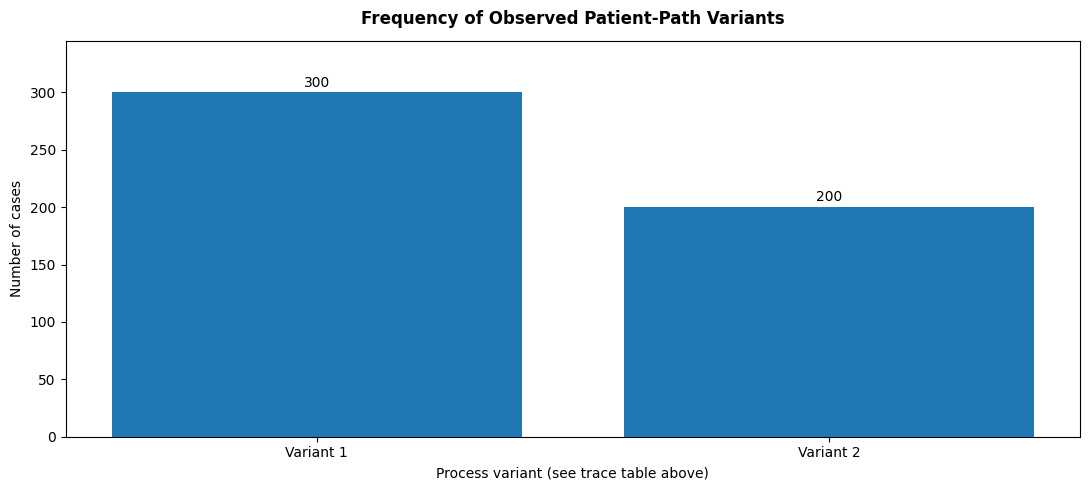

In [ ]:
variant_summary = (
    case_metrics.groupby("Case_Trace", as_index=False)
    .agg(Case_Count=("Case_ID", "nunique"), Mean_Throughput_Minutes=("Case_Duration_Minutes", "mean"))
    .sort_values("Case_Count", ascending=False)
    .reset_index(drop=True)
)
variant_summary["Share_Percent"] = 100 * variant_summary["Case_Count"] / n_cases

display(variant_summary.round({"Mean_Throughput_Minutes": 1, "Share_Percent": 1}))

fig, ax = plt.subplots(figsize=(11, 5))
labels = [f"Variant {i+1}" for i in range(len(variant_summary))]
ax.bar(labels, variant_summary["Case_Count"])
ax.set_title("Frequency of Observed Patient-Path Variants", pad=12, weight="bold")
ax.set_ylabel("Number of cases")
ax.set_xlabel("Process variant (see trace table above)")
for i, value in enumerate(variant_summary["Case_Count"]):
    ax.text(i, value + max(1, n_cases * 0.01), f"{value:,}", ha="center", fontsize=10)
ax.set_ylim(0, max(variant_summary["Case_Count"]) * 1.15)
plt.tight_layout()
plt.show()

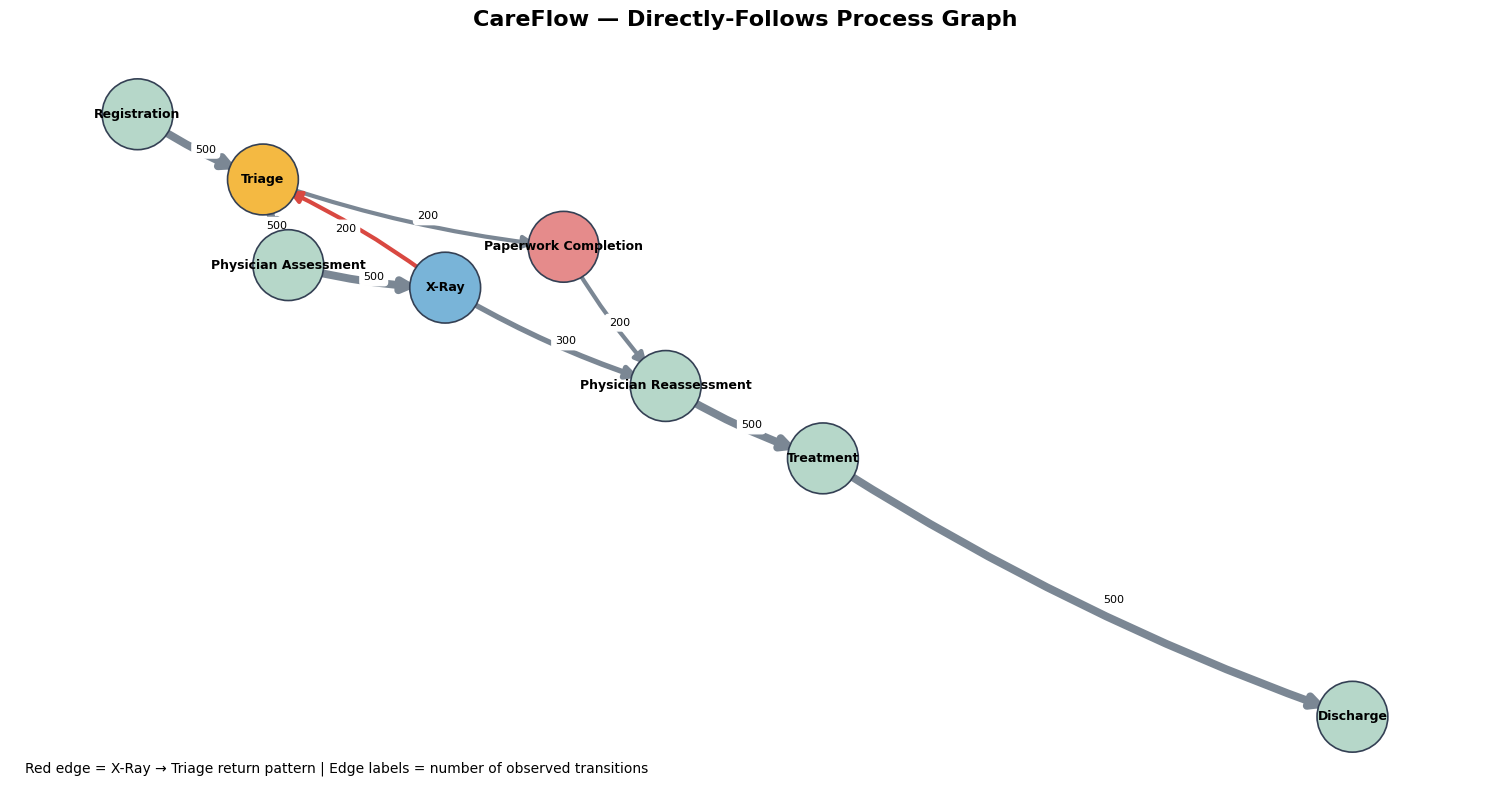

,Activity_Name,Next_Activity,Transition_Count
0,Physician Assessment,X-Ray,500
1,Triage,Physician Assessment,500
2,Physician Reassessment,Treatment,500
3,Registration,Triage,500
4,Treatment,Discharge,500
5,X-Ray,Physician Reassessment,300
6,Paperwork Completion,Physician Reassessment,200
7,Triage,Paperwork Completion,200
8,X-Ray,Triage,200


In [ ]:
edge_counts = (
    transitions.groupby(["Activity_Name", "Next_Activity"], as_index=False)
    .size()
    .rename(columns={"size": "Transition_Count"})
)

process_graph = nx.DiGraph()
for activity in event_log["Activity_Name"].dropna().astype(str).unique():
    process_graph.add_node(activity)
for row in edge_counts.itertuples(index=False):
    process_graph.add_edge(row.Activity_Name, row.Next_Activity, weight=int(row.Transition_Count))

positions = nx.spring_layout(process_graph, seed=RANDOM_SEED, k=1.25, iterations=100)
weights = [process_graph[u][v]["weight"] for u, v in process_graph.edges()]
max_weight = max(weights) if weights else 1
edge_widths = [1.2 + 4.5 * w / max_weight for w in weights]
edge_colors = ["#D94841" if (u == "X-Ray" and v == "Triage") else "#7B8794" for u, v in process_graph.edges()]
node_colors = []
for node in process_graph.nodes():
    if node == "Triage":
        node_colors.append("#F4B942")
    elif node == "X-Ray":
        node_colors.append("#79B4D8")
    elif node == "Paperwork Completion":
        node_colors.append("#E58B8B")
    else:
        node_colors.append("#B6D7C9")

fig, ax = plt.subplots(figsize=(15, 8))
nx.draw_networkx_nodes(process_graph, positions, node_size=2600, node_color=node_colors, edgecolors="#344054", linewidths=1.2, ax=ax)
nx.draw_networkx_labels(process_graph, positions, font_size=9, font_weight="bold", ax=ax)
nx.draw_networkx_edges(process_graph, positions, width=edge_widths, edge_color=edge_colors, arrows=True, arrowsize=18, connectionstyle="arc3,rad=0.06", min_source_margin=18, min_target_margin=20, ax=ax)
nx.draw_networkx_edge_labels(process_graph, positions, edge_labels={(u, v): process_graph[u][v]["weight"] for u, v in process_graph.edges()}, font_size=8, label_pos=0.55, rotate=False, ax=ax)
ax.set_title("CareFlow — Directly-Follows Process Graph", fontsize=16, weight="bold", pad=18)
ax.text(0.01, 0.01, "Red edge = X-Ray → Triage return pattern | Edge labels = number of observed transitions", transform=ax.transAxes, fontsize=10)
ax.axis("off")
plt.tight_layout()
plt.show()

display(edge_counts.sort_values("Transition_Count", ascending=False).reset_index(drop=True))

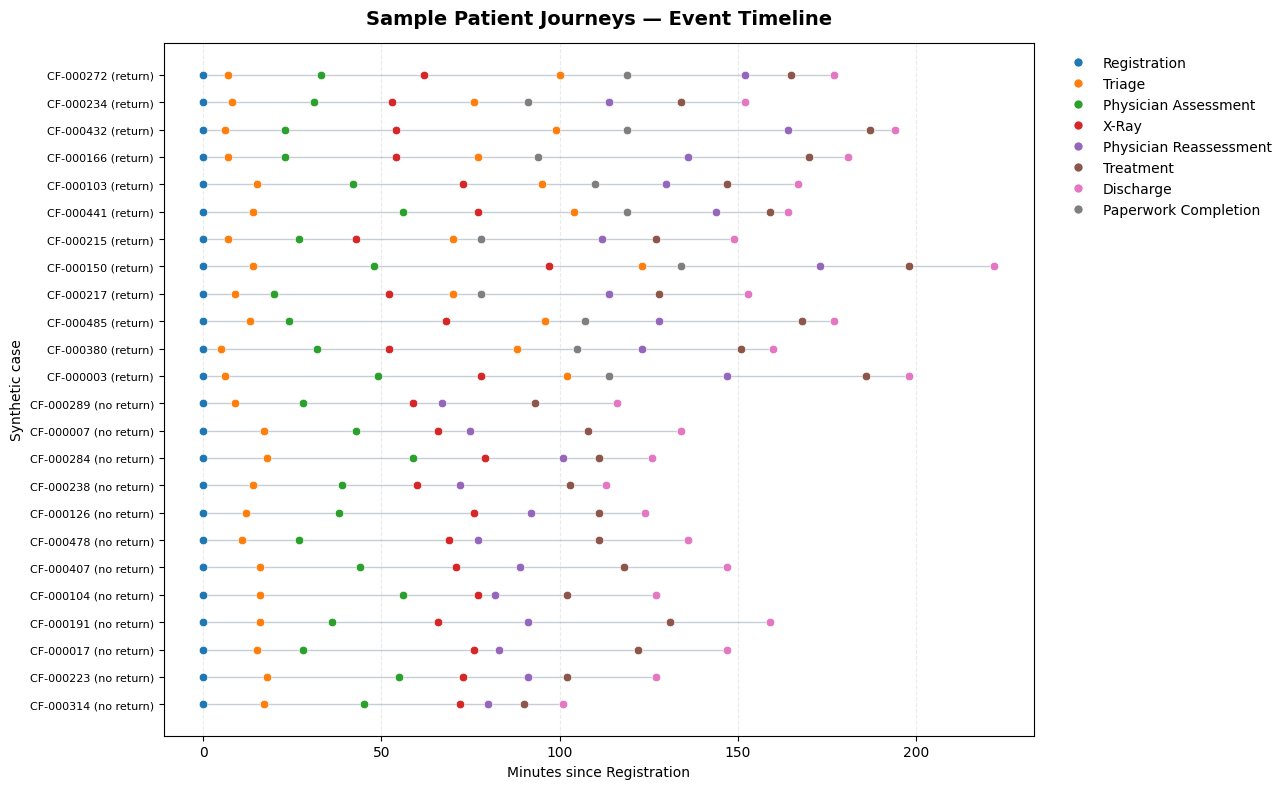

In [ ]:
rng = np.random.default_rng(RANDOM_SEED + 1)
return_cases = case_metrics.loc[case_metrics["Returned_To_Triage_After_XRay"], "Case_ID"].to_numpy()
nonreturn_cases = case_metrics.loc[~case_metrics["Returned_To_Triage_After_XRay"], "Case_ID"].to_numpy()
n_each = min(12, len(return_cases), len(nonreturn_cases))
sample_ids = list(rng.choice(nonreturn_cases, size=n_each, replace=False)) + list(rng.choice(return_cases, size=n_each, replace=False))
sample_events = event_log[event_log["Case_ID"].isin(sample_ids)].copy()
case_start = sample_events.groupby("Case_ID")["Timestamp"].transform("min")
sample_events["Minutes_From_Registration"] = (sample_events["Timestamp"] - case_start).dt.total_seconds() / 60

case_order = case_metrics.set_index("Case_ID").loc[sample_ids].sort_values("Returned_To_Triage_After_XRay").index.tolist()
y_position = {case_id: pos for pos, case_id in enumerate(case_order)}
sample_events["Case_Y"] = sample_events["Case_ID"].map(y_position)
activity_names = list(event_log["Activity_Name"].astype(str).unique())
color_palette = plt.get_cmap("tab10")
activity_colors = {activity: color_palette(i % 10) for i, activity in enumerate(activity_names)}

fig, ax = plt.subplots(figsize=(13, 8))
for case_id, group in sample_events.groupby("Case_ID", sort=False):
    group = group.sort_values("Timestamp")
    y = y_position[case_id]
    ax.plot(group["Minutes_From_Registration"], [y] * len(group), color="#AAB2BD", linewidth=1.0, alpha=0.65, zorder=1)
    for row in group.itertuples(index=False):
        ax.scatter(row.Minutes_From_Registration, y, s=38, color=activity_colors[str(row.Activity_Name)], edgecolor="white", linewidth=0.5, zorder=2)

ax.set_yticks(range(len(case_order)))
ax.set_yticklabels([f"{case_id} ({'return' if bool(case_metrics.set_index('Case_ID').loc[case_id, 'Returned_To_Triage_After_XRay']) else 'no return'})" for case_id in case_order], fontsize=8)
ax.set_xlabel("Minutes since Registration")
ax.set_ylabel("Synthetic case")
ax.set_title("Sample Patient Journeys — Event Timeline", fontsize=14, weight="bold", pad=14)
handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=activity_colors[a], markeredgecolor="white", markersize=7, label=a) for a in activity_names]
ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
ax.grid(axis="x", linestyle="--", alpha=0.25)
plt.tight_layout()
plt.show()

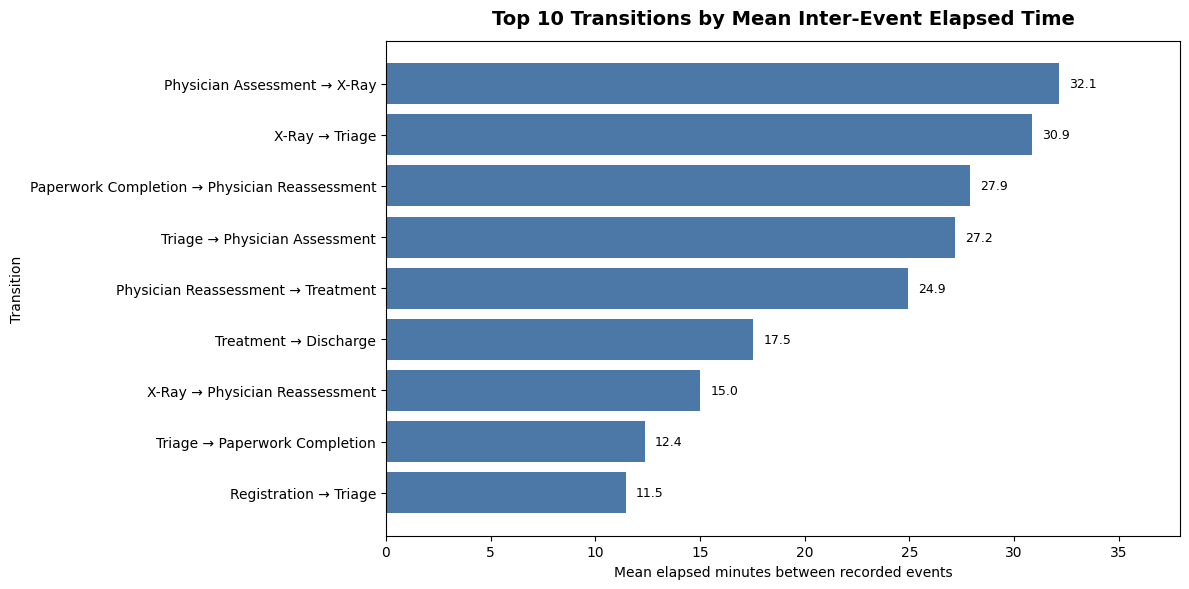

,Activity_Name,Next_Activity,Transition,Transition_Count,Mean_Elapsed_Minutes,Median_Elapsed_Minutes,P90_Elapsed_Minutes
0,Physician Assessment,X-Ray,Physician Assessment → X-Ray,500,32.15,32.0,47.0
1,X-Ray,Triage,X-Ray → Triage,200,30.85,31.0,44.0
2,Paperwork Completion,Physician Reassessment,Paperwork Completion → Physician Reassessment,200,27.88,28.0,42.0
3,Triage,Physician Assessment,Triage → Physician Assessment,500,27.18,27.0,42.0
4,Physician Reassessment,Treatment,Physician Reassessment → Treatment,500,24.95,25.0,37.0
5,Treatment,Discharge,Treatment → Discharge,500,17.55,17.0,28.0
6,X-Ray,Physician Reassessment,X-Ray → Physician Reassessment,300,15.00,15.0,24.0
7,Triage,Paperwork Completion,Triage → Paperwork Completion,200,12.36,12.0,19.0
8,Registration,Triage,Registration → Triage,500,11.45,12.0,17.0


Reminder: inter-event elapsed time is a proxy until explicit queue and service timestamps are available.


In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))
plot_data = transition_summary.head(10).sort_values("Mean_Elapsed_Minutes", ascending=True)
ax.barh(plot_data["Transition"], plot_data["Mean_Elapsed_Minutes"], color="#4C78A8")
ax.set_title("Top 10 Transitions by Mean Inter-Event Elapsed Time", fontsize=14, weight="bold", pad=12)
ax.set_xlabel("Mean elapsed minutes between recorded events")
ax.set_ylabel("Transition")
for y, value in enumerate(plot_data["Mean_Elapsed_Minutes"]):
    ax.text(value + 0.5, y, f"{value:.1f}", va="center", fontsize=9)
ax.set_xlim(0, plot_data["Mean_Elapsed_Minutes"].max() * 1.18)
plt.tight_layout()
plt.show()

display(transition_summary.head(15).round(2))

print("Reminder: inter-event elapsed time is a proxy until explicit queue and service timestamps are available.")

,Measure,Count,Rate_Percent
0,Total cases,500,100.0
1,Cases with X-Ray → Triage,200,40.0
2,Cases without X-Ray → Triage,300,60.0


,Arrival_Shift,Cases,Return_Cases,Return_Rate_Percent
0,Afternoon (12:00–17:59),133,56,42.1
1,Morning (06:00–11:59),109,39,35.8
2,Night (18:00–05:59),258,105,40.7


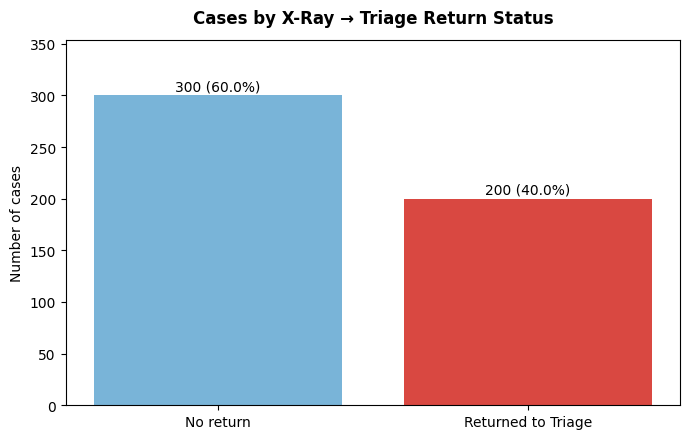

Observed synthetic return rate: 40.0% (200/500 cases).
Recorded root-cause label for injected return events: Missing intake paperwork.


In [ ]:
loopback_summary = pd.DataFrame([
    {"Measure": "Total cases", "Count": n_cases, "Rate_Percent": 100.0},
    {"Measure": "Cases with X-Ray → Triage", "Count": n_returned, "Rate_Percent": 100 * n_returned / n_cases if n_cases else np.nan},
    {"Measure": "Cases without X-Ray → Triage", "Count": n_cases - n_returned, "Rate_Percent": 100 * (n_cases - n_returned) / n_cases if n_cases else np.nan},
])
display(loopback_summary.round(1))

return_by_shift = (
    case_metrics.groupby("Arrival_Shift", as_index=False)
    .agg(Cases=("Case_ID", "nunique"), Return_Cases=("Returned_To_Triage_After_XRay", "sum"))
)
return_by_shift["Return_Rate_Percent"] = 100 * return_by_shift["Return_Cases"] / return_by_shift["Cases"]
display(return_by_shift.round(1))

fig, ax = plt.subplots(figsize=(7, 4.5))
labels = ["No return", "Returned to Triage"]
values = [n_cases - n_returned, n_returned]
ax.bar(labels, values, color=["#79B4D8", "#D94841"])
ax.set_title("Cases by X-Ray → Triage Return Status", weight="bold", pad=12)
ax.set_ylabel("Number of cases")
for i, value in enumerate(values):
    ax.text(i, value + max(1, n_cases * 0.01), f"{value:,} ({value/n_cases:.1%})", ha="center")
ax.set_ylim(0, max(values) * 1.18)
plt.tight_layout()
plt.show()

observed_return_rate = n_returned / n_cases if n_cases else 0
print(f"Observed synthetic return rate: {observed_return_rate:.1%} ({n_returned:,}/{n_cases:,} cases).")
print("Recorded root-cause label for injected return events: Missing intake paperwork.")

In [ ]:
IDEAL_PATH = [
    "Registration",
    "Triage",
    "Physician Assessment",
    "X-Ray",
    "Physician Reassessment",
    "Treatment",
    "Discharge",
]
IDEAL_TRACE = " → ".join(IDEAL_PATH)

conformance_results = case_metrics[[
    "Case_ID", "Case_Trace", "Case_Duration_Minutes", "Returned_To_Triage_After_XRay", "Age_Band", "Arrival_Shift"
]].copy()
conformance_results["Conforms_To_Baseline"] = conformance_results["Case_Trace"].eq(IDEAL_TRACE)
conformance_results["Deviation_Reason"] = np.where(
    conformance_results["Returned_To_Triage_After_XRay"],
    "Rework loop: returned to Triage after X-Ray (synthetic missing-paperwork scenario)",
    np.where(conformance_results["Conforms_To_Baseline"], "No deviation — follows baseline pathway", "Other sequence deviation — review trace"),
)

conformance_summary = pd.DataFrame([
    {"Measure": "Cases assessed", "Count": len(conformance_results), "Percent": 100.0},
    {"Measure": "Conforming cases", "Count": int(conformance_results["Conforms_To_Baseline"].sum()), "Percent": 100 * conformance_results["Conforms_To_Baseline"].mean()},
    {"Measure": "Non-conforming cases", "Count": int((~conformance_results["Conforms_To_Baseline"]).sum()), "Percent": 100 * (~conformance_results["Conforms_To_Baseline"]).mean()},
])
display(conformance_summary.round(1))
display(conformance_results.head(10))

,Measure,Count,Percent
0,Cases assessed,500,100.0
1,Conforming cases,300,60.0
2,Non-conforming cases,200,40.0


,Case_ID,Case_Trace,Case_Duration_Minutes,Returned_To_Triage_After_XRay,Age_Band,Arrival_Shift,Conforms_To_Baseline,Deviation_Reason
0,CF-000001,Registration → Triage → Physician Assessment →...,96.0,False,40–64,Afternoon (12:00–17:59),True,No deviation — follows baseline pathway
1,CF-000002,Registration → Triage → Physician Assessment →...,147.0,False,18–39,Night (18:00–05:59),True,No deviation — follows baseline pathway
2,CF-000003,Registration → Triage → Physician Assessment →...,198.0,True,18–39,Afternoon (12:00–17:59),False,Rework loop: returned to Triage after X-Ray (s...
3,CF-000004,Registration → Triage → Physician Assessment →...,121.0,False,0–17,Night (18:00–05:59),True,No deviation — follows baseline pathway
4,CF-000005,Registration → Triage → Physician Assessment →...,129.0,False,65+,Afternoon (12:00–17:59),True,No deviation — follows baseline pathway
5,CF-000006,Registration → Triage → Physician Assessment →...,142.0,False,18–39,Morning (06:00–11:59),True,No deviation — follows baseline pathway
6,CF-000007,Registration → Triage → Physician Assessment →...,134.0,False,40–64,Night (18:00–05:59),True,No deviation — follows baseline pathway
7,CF-000008,Registration → Triage → Physician Assessment →...,125.0,False,0–17,Night (18:00–05:59),True,No deviation — follows baseline pathway
8,CF-000009,Registration → Triage → Physician Assessment →...,63.0,False,18–39,Afternoon (12:00–17:59),True,No deviation — follows baseline pathway
9,CF-000010,Registration → Triage → Physician Assessment →...,129.0,False,40–64,Afternoon (12:00–17:59),True,No deviation — follows baseline pathway


In [ ]:
if PM4PY_AVAILABLE:
    pm4py_event_log = event_log[["Case_ID", "Activity_Name", "Timestamp"]].rename(columns={
        "Case_ID": "case:concept:name",
        "Activity_Name": "concept:name",
        "Timestamp": "time:timestamp",
    }).copy()
    pm4py_event_log["time:timestamp"] = pd.to_datetime(pm4py_event_log["time:timestamp"], errors="raise")

    try:
        discovered_dfg, start_activities, end_activities = pm4py.discover_dfg(pm4py_event_log)
        print("PM4Py directly-follows discovery completed.")
        print("Start activities:", start_activities)
        print("End activities:", end_activities)
        display(pd.DataFrame(
            [(str(source), str(target), int(count)) for (source, target), count in discovered_dfg.items()],
            columns=["Source", "Target", "Frequency"],
        ).sort_values("Frequency", ascending=False).reset_index(drop=True).head(20))
    except Exception as exc:
        print(f"PM4Py DFG discovery did not complete in this PM4Py version: {type(exc).__name__}: {exc}")
        print("The native NetworkX directly-follows graph above remains available.")

    try:
        petri_net, initial_marking, final_marking = pm4py.discover_petri_net_inductive(pm4py_event_log)
        print("PM4Py inductive Petri-net discovery completed.")
        print(f"Petri net places: {len(petri_net.places)} | transitions: {len(petri_net.transitions)}")
    except Exception as exc:
        print(f"PM4Py inductive discovery was unavailable in this version: {type(exc).__name__}: {exc}")
else:
    print("PM4Py is not installed in this environment; native DFG and baseline conformance analysis above have run.")
    print("To enable PM4Py discovery, install requirements.txt and restart the notebook kernel.")

PM4Py is not installed in this environment; native DFG and baseline conformance analysis above have run.
To enable PM4Py discovery, install requirements.txt and restart the notebook kernel.


In [ ]:
artifacts = {
    "clean_event_log.csv": event_log,
    "case_metrics.csv": case_metrics,
    "transition_bottlenecks.csv": transition_summary,
    "process_variants.csv": variant_summary,
    "process_transitions.csv": edge_counts,
    "conformance_results.csv": conformance_results,
    "data_quality_report.csv": quality_report,
}

for filename, frame in artifacts.items():
    destination = OUTPUT_DIR / filename
    export_frame = frame.copy()
    export_frame.to_csv(destination, index=False)
    print(f"Saved {destination} ({len(export_frame):,} rows)")

print("\nCareFlow local analysis artifacts are ready.")

Saved careflow_data/clean_event_log.csv (3,900 rows)
Saved careflow_data/case_metrics.csv (500 rows)
Saved careflow_data/transition_bottlenecks.csv (9 rows)
Saved careflow_data/process_variants.csv (2 rows)
Saved careflow_data/process_transitions.csv (9 rows)
Saved careflow_data/conformance_results.csv (500 rows)
Saved careflow_data/data_quality_report.csv (6 rows)

CareFlow local analysis artifacts are ready.
